## Why Adult

The MNIST page shows the effect under controlled conditions. Adult asks whether it shows up for real people. The data is the UCI Adult dataset (1994 US Census), the task is predicting whether income exceeds **\$50K**, and the protected attribute is **sex**.

The design choice that matters most is that we **balance the two groups** to about 14,700 people each. Neither group is underrepresented, so any extra cost one group pays comes from how **hard** that group is to learn, not from how *rare* it is. In this setup **men are the harder group**: they have lower accuracy and, per Esipova et al. (Fig. 8), larger gradients. This is a *subgroup disparity* on balanced groups, not the class imbalance studied on MNIST.

## Setup

- **Data:** the paper's preprocessing (Esipova et al., App. B.1):
  - drop rows with missing values (48,842 → 45,222; 30,527 men, 14,695 women);
  - drop `fnlwgt` and binarize race (white / non-white);
  - standardize the numeric features and one-hot encode the categoricals;
  - **balance by sex** by keeping every woman and a random 14,695 / 30,527 share of men;
  - split 80/20 into train and test.
  - Sex stays an input feature (98 inputs).
- **Model:** an MLP with two hidden layers of 256 units and tanh (91,650 parameters).
- **Training:** cross-entropy, plain SGD, 20 epochs, batch size 256. Private runs use Poisson sampling and an RDP accountant with $\delta = 10^{-6}$.
- **Seeds:** five (0–4). Within a seed, every method sees the same split and starts from the same initial weights.

In [1]:
import pandas as pd
from dpdisparity import analysis as A, plots, runner

SOURCE = "legacy"  # "legacy" = frozen dp-testing runs; "rerun" = train any missing runs with this repo's pipeline

In [2]:
#| label: tbl-adult-settings
#| tbl-cap: "Hyperparameters per method (Esipova et al., App. B)."
A.settings_table("adult")

,epochs,lr,batch_size,σ,C,Z₀,τ,σ₂,η_Z,δ
Non-private,20,0.01,256,,,,,,,1e-06
DP-SGD,20,0.01,256,1.0,0.5,,,,,1e-06
Global-Adapt,20,0.2,256,1.0,0.5,50.0,1.0,10.0,0.1,1e-06


In [3]:
results = runner.load("adult", SOURCE)
df = A.to_frame(results)
acc = A.summarize(df, "accuracy")
SEXES = ["Male", "Female"]

## Phase 1: Non-private baseline

Without privacy, the model is about **81%** accurate for men and **92%** for women. Part of the reason is the base rate. Only about 12% of women in the test set earn over \$50K, against about 32% of men, so for women "≤ \$50K" is usually the right answer.

In [4]:
#| label: tbl-adult-base
#| tbl-cap: "Test set per sex (ours, mean over seeds): size, share earning > \\$50K, and the accuracy of always predicting ≤ \\$50K."
base = df[df.method == "nonprivate"].assign(share_over_50k=lambda d: 100 * (d.fn + d.tp) / d.n)
base = base.groupby("group")[["n", "share_over_50k"]].mean().loc[SEXES]
base.assign(always_predict_under_50k=100 - base.share_over_50k).round(1)

,n,share_over_50k,always_predict_under_50k
group,,,
Male,2964.0,31.5,68.5
Female,2922.8,11.6,88.4


## Phase 2: DP-SGD

With DP-SGD ($C = 0.5$, $\sigma = 1$, $\varepsilon \approx 3.41$), both groups lose accuracy, but men lose much more: about 11 points against about 4 for women.

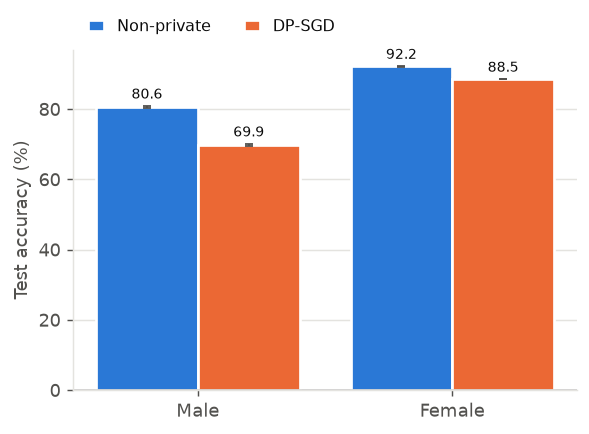

In [5]:
#| label: fig-adult-dpsgd
#| fig-cap: "Test accuracy by sex, non-private vs DP-SGD (ours; mean ± SE over 5 seeds)."
plots.group_bars(acc[acc.method != "global_adapt"], SEXES, "Test accuracy (%)", label_groups=SEXES);

## Phase 3: Disparity evaluation

The privacy cost is $\pi_k = A_k(\text{non-private}) - A_k(\text{private})$, paired by seed. The disparity measure is the **privacy-cost gap** $\lvert \pi_{\text{Male}} - \pi_{\text{Female}} \rvert$.

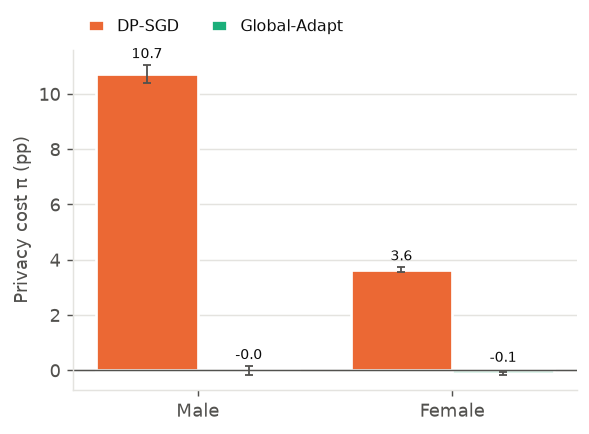

In [6]:
#| label: fig-adult-cost
#| fig-cap: "Privacy cost by sex (ours; percentage points lost relative to the non-private model)."
plots.group_bars(A.summarize(A.privacy_costs(df), "pi"), SEXES, "Privacy cost π (pp)", label_groups=SEXES);

### Accuracy hides failure

Accuracy alone makes DP-SGD look tolerable for women (about 88.5%). The **false-negative rate** shows more: it is the share of real high earners the model labels "≤ \$50K". Under DP-SGD the model misses about 95% of high-earning men and 98% of high-earning women, so it almost always predicts "≤ \$50K". Its accuracy is close to that of the constant "always ≤ \$50K" predictor in the table above: 88.4% for women and 68.5% for men.

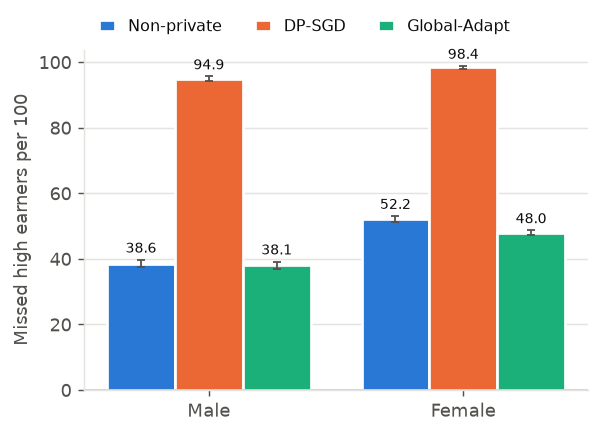

In [7]:
#| label: fig-adult-fnr
#| fig-cap: "False-negative rate by sex: real high earners the model misses, per 100 (ours; mean ± SE over 5 seeds)."
plots.group_bars(A.summarize(df, "fnr"), SEXES, "Missed high earners per 100", label_groups=SEXES);

**An observation of ours to examine further, not a published result.** A model that falls back to the majority answer loses roughly the accuracy it had *above* that constant baseline:

| Sex | Non-private accuracy above the constant baseline | DP-SGD privacy cost |
|---|---|---|
| Men | about 12 points | about 10.7 |
| Women | about 4 points | about 3.7 |

So on Adult, the privacy-cost gap may partly reflect how much each group's non-private model had learned beyond the base rate. That is in line with Demelius et al. (2025): conclusions depend on the metric chosen. It is a reason to report FNR and similar measures next to accuracy.

## Phase 4: DPSGD-Global-Adapt

Global-Adapt scales every gradient by the same factor $C/Z$ instead of clipping large gradients separately, and learns $Z$ privately. Its noisy count is charged to the privacy budget, giving $\varepsilon \approx 3.42$ instead of 3.41. It uses no group labels.

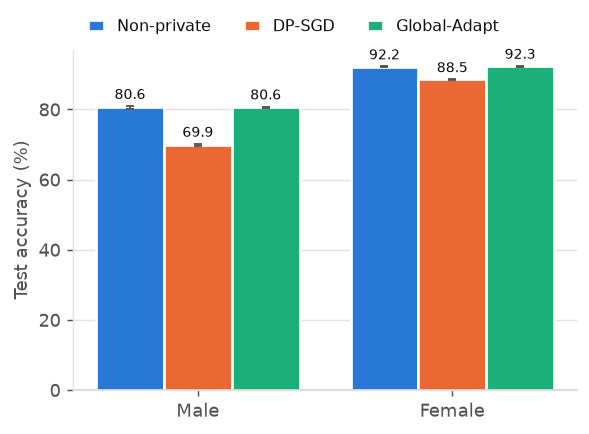

In [8]:
#| label: fig-adult-acc
#| fig-cap: "Test accuracy by sex for all three methods (ours; mean ± SE over 5 seeds)."
plots.group_bars(acc, SEXES, "Test accuracy (%)", label_groups=SEXES);

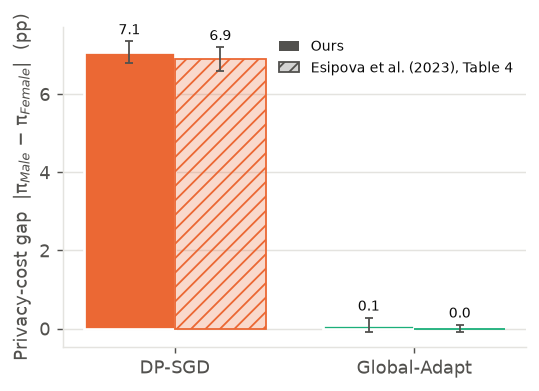

In [9]:
#| label: fig-adult-gap
#| fig-cap: "Privacy-cost gap $\\lvert \\pi_{\\text{Male}} - \\pi_{\\text{Female}} \\rvert$: ours vs Esipova et al. (2023), Table 4. Mean ± SE over 5 seeds."
plots.gap_bars(A.gaps(df, "adult"), "adult");

On balanced Adult, Global-Adapt recovers essentially all of the accuracy DP-SGD lost. Both groups end within about 0.1 points of the non-private model, and the privacy-cost gap falls from about 7 points to about 0.1 ± 0.2. The false-negative rates also fall back to about their non-private levels, so the model is actually identifying high earners again rather than falling back to the majority answer.

**A caveat on the comparison:** Global-Adapt is trained with a learning rate of 0.2 and DP-SGD with 0.01, following the paper. Part of the improvement may come from the larger step size rather than the scaling rule. A matched-learning-rate check is a planned next step.

## Comparison with the paper

Every value below is mean ± standard error over 5 seeds, in percentage points. "Ours" rows are our runs. The other rows are Esipova et al.'s published numbers.

In [10]:
#| label: tbl-adult-compare
#| tbl-cap: "Ours vs Esipova et al. (2023), Table 4. Mean ± SE over 5 seeds."
A.comparison_table(results, "adult")

Acc Male  Acc Female  \
Method       Source                                                   
Non-private  Ours                            80.6 ± 0.4  92.2 ± 0.1   
             Esipova et al. (2023), Table 4  80.5 ± 0.4  92.2 ± 0.1   
DP-SGD       Ours                            69.9 ± 0.3  88.5 ± 0.1   
             Esipova et al. (2023), Table 4  69.9 ± 0.4  88.5 ± 0.1   
Global-Adapt Ours                            80.6 ± 0.3  92.3 ± 0.1   
             Esipova et al. (2023), Table 4  80.7 ± 0.4  92.3 ± 0.1   

                                                 π Male    π Female  \
Method       Source                                                   
Non-private  Ours                                     –           –   
             Esipova et al. (2023), Table 4           –           –   
DP-SGD       Ours                            10.7 ± 0.3   3.6 ± 0.1   
             Esipova et al. (2023), Table 4  10.6 ± 0.3   3.6 ± 0.1   
Global-Adapt Ours                            -0.0 ± 0.2  -0.1 ± 0.1   
             Esipova et al. (2023), Table 4  -0.1 ± 0.1  -0.1 ± 0.1   

                                             Gap π Male,Female     ε  
Method       Source                                                   
Non-private  Ours                            0 (by definition)     –  
             Esipova et al. (2023), Table 4  0 (by definition)     –  
DP-SGD       Ours                                    7.1 ± 0.3  3.41  
             Esipova et al. (2023), Table 4          6.9 ± 0.3     –  
Global-Adapt Ours                                    0.1 ± 0.2  3.42  
             Esipova et al. (2023), Table 4          0.0 ± 0.1     –

Our results **closely track** the paper:

- every accuracy is within about 0.1 points;
- the DP-SGD gap is 7.1 ± 0.3 vs 6.9 ± 0.3;
- the Global-Adapt gap is 0.1 ± 0.2 vs 0.0 ± 0.1.

**Points still to verify against the authors' code** (`fair-dp@c61a163`):

- **Sex balancing:** whether their loader balances the same way (ours keeps every woman and samples men).
- **Sex as an input:** whether sex is an input feature. The paper's parameter count suggests it is.
- **Global-Adapt's count:** whether it is normalized by the realized or the expected batch size.
- **Global-Adapt's $\varepsilon$:** the paper reports that it matches DP-SGD to three significant digits. Ours is 3.42 vs 3.41.

## Reproducibility check: rerunning in this repository

The numbers above come from the original `dp-testing` runs. All of Adult was retrained here with this repository's ported pipeline (`uv run python scripts/sweep.py --dataset adult`), on CPU and with newer library versions. Exact agreement is not expected, because GPU vs CPU and different library versions change the random noise draws. Close agreement shows the port behaves the same.

On $\varepsilon$: for seeds 1 and 2 the balanced training set gives 93 batches per epoch, so the sampling rate is $q = 1/93$. Opacus then takes 92 steps per epoch, which gives $\varepsilon \approx 3.37$ for those seeds in the rerun. The dp-testing files report 3.41 for every seed, which matches $q = 1/92$. The legacy figure is therefore slightly conservative for two seeds.

In [11]:
#| label: tbl-adult-rerun
#| tbl-cap: "Key numbers (means over 5 seeds): original dp-testing runs vs this repository's rerun."
pd.DataFrame({"dp-testing": A.headline(runner.load("adult", "legacy"), "adult"),
              "this repo (rerun)": A.headline(runner.load("adult", "rerun"), "adult")})

,dp-testing,this repo (rerun)
Non-private: Acc Male,80.57,80.59
Non-private: Acc Female,92.18,92.18
DP-SGD: Acc Male,69.86,69.90
DP-SGD: Acc Female,88.54,88.54
Global-Adapt: Acc Male,80.57,80.68
Global-Adapt: Acc Female,92.29,92.30
DP-SGD: gap,7.07,7.05
Global-Adapt: gap,0.10,0.04
DP-SGD: ε,3.41,3.39
Global-Adapt: ε,3.42,3.40


## Run details

In [12]:
#| label: tbl-adult-runs
#| tbl-cap: "Achieved privacy (RDP accountant) and final $Z$, means over seeds."
A.run_info(results)

,seeds,epsilon,delta,final_Z,source
method,,,,,
Non-private,5,–,–,–,dp-testing
DP-SGD,5,3.408,1e-06,–,dp-testing
Global-Adapt,5,3.415,1e-06,6.98,dp-testing


## Takeaways

- **The harder group pays more, even at equal size.** With balanced groups, DP-SGD costs men about 11 points of accuracy and women about 4. The disparity comes from difficulty, not underrepresentation.
- **Accuracy understates the damage.** DP-SGD misses about 95–98% of real high earners in both groups. Women's accuracy stays high mostly because of their low base rate.
- **Global-Adapt nearly closes the gap here** (about 0.1 ± 0.2 points), unlike on MNIST, where it only shrinks it. The learning-rate difference between the methods is a caveat still to check.